# Лабораторная работа 9. Работа с изображениями, часть 2 (использование нейронных сетей)

## 1.1. Разделение изображений на train, validation и test

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [5]:
from pathlib import Path
import shutil
import pandas as pd
from sklearn.model_selection import train_test_split

SOURCE_DIR = Path('lab_08_data/cats_vs_dogs')
DATA_DIR = Path('lab_09_data/dataset')

rows = []
for label, class_name in enumerate(['dogs', 'cats']):
    for path in sorted((SOURCE_DIR / class_name).glob('*.jpg')):
        rows.append({'filepath': str(path), 'class_name': class_name, 'label': label})

class_names = ['dogs', 'cats']

df = pd.DataFrame(rows)

In [6]:
train_df, remaining_df = train_test_split(
    df, test_size=0.30, stratify=df['label'], random_state=42
)
val_df, test_df = train_test_split(
    remaining_df, test_size=0.50,
    stratify=remaining_df['label'], random_state=42
)

In [7]:
for split, part in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    for row in part.itertuples():
        folder = DATA_DIR / split / row.class_name
        folder.mkdir(parents=True, exist_ok=True)
        shutil.copy2(row.filepath, folder / Path(row.filepath).name)
    print(f'{split}: {len(part)} изображений')

train: 140 изображений
validation: 30 изображений
test: 30 изображений


In [8]:
for name, part in [
    ('Train', train_df),
    ('Validation', val_df),
    ('Test', test_df)
]:
    print(f'\n{name}:')
    print(part['label'].map(dict(enumerate(class_names))).value_counts())


Train:
label
dogs    70
cats    70
Name: count, dtype: int64

Validation:
label
dogs    15
cats    15
Name: count, dtype: int64

Test:
label
dogs    15
cats    15
Name: count, dtype: int64


In [9]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label): 
    image = tf.io.read_file(filepath)

    image = tf.image.decode_image(
        image, 
        channels = 3, 
        expand_animations = False
    )

    image = tf.image.resize(image,[IMG_SIZE, IMG_SIZE])
    image = tf.ensure_shape(image, [IMG_SIZE, IMG_SIZE, 3])

    return image, label

def create_dataset(dataframe, shuffle=False): 

    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe['filepath'].values, 
        dataframe['label'].values
    ))

    dataset = dataset.map(
            load_image,
            num_parallel_calls=AUTOTUNE
        )
    
    if shuffle:
            dataset = dataset.shuffle(
                buffer_size=len(dataframe),
                seed=42
            )
            
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset
    
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

In [10]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

In [11]:
import tensorflow as tf 

from tensorflow.keras import layers, models

IMG_SIZE = (224, 224)
BATCH_SIZE = 32


In [12]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(*IMG_SIZE, 3)),

    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),

    tf.keras.layers.MaxPooling2D(), 

    tf.keras.layers.Conv2D(64, 3, activation='relu'),

    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation='relu'),

    tf.keras.layers.GlobalAveragePooling2D(), 

    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

Epoch 1/50


e:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\lab_01\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 339ms/step - accuracy: 0.4714 - loss: 0.6996 - precision: 0.4545 - recall: 0.2857 - val_accuracy: 0.5333 - val_loss: 0.6931 - val_precision: 0.5185 - val_recall: 0.9333
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 284ms/step - accuracy: 0.6000 - loss: 0.6907 - precision: 0.5854 - recall: 0.6857 - val_accuracy: 0.5333 - val_loss: 0.6916 - val_precision: 0.5333 - val_recall: 0.5333
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 270ms/step - accuracy: 0.5714 - loss: 0.6891 - precision: 0.5490 - recall: 0.8000 - val_accuracy: 0.4667 - val_loss: 0.6905 - val_precision: 0.4706 - val_recall: 0.5333
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 279ms/step - accuracy: 0.5500 - loss: 0.6877 - precision: 0.5285 - recall: 0.9286 - val_accuracy: 0.5333 - val_loss: 0.6869 - val_precision: 0.5385 - val_recall: 0.4667
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 272ms/step - accuracy: 0.5571 - loss: 0.6812 - precision: 0.6176 - recall: 0.3000 - val_accuracy: 0.5333 - val_loss: 0.6846 - val_precision:

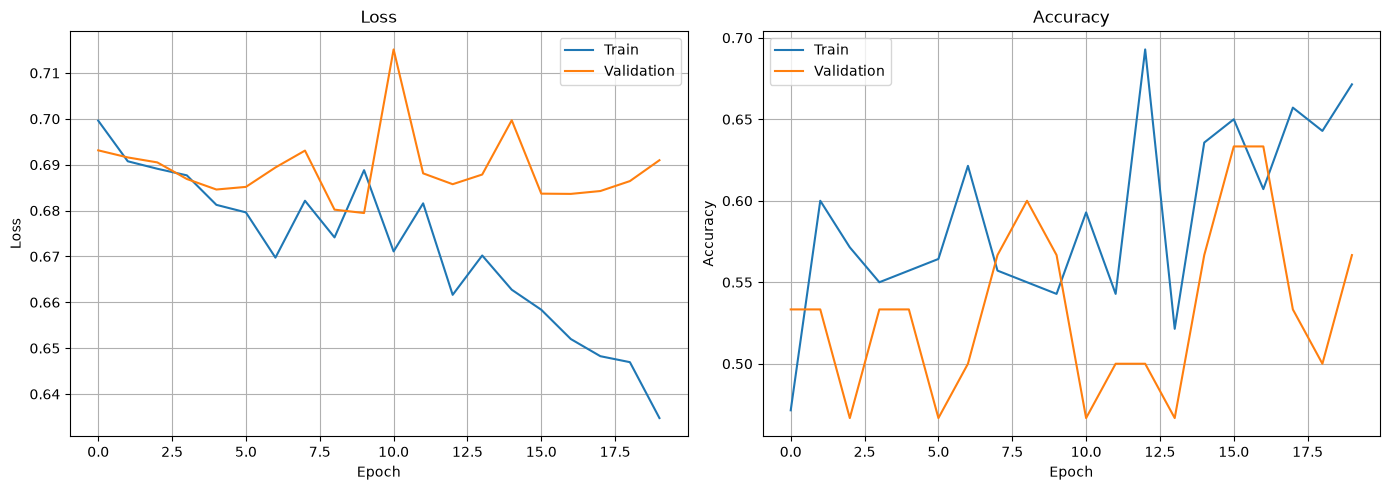

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid()

# Accuracy
axes[1].plot(history.history['accuracy'], label='Train')
axes[1].plot(history.history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [16]:
test_loss, test_accuracy, test_precision, test_recall = model.evaluate(test_ds)

print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')
print(f'Test Precision: {test_precision:.4f}')
print(f'Test Recall: {test_recall:.4f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.6333 - loss: 0.6607 - precision: 0.6250 - recall: 0.6667
Test Loss: 0.6607
Test Accuracy: 0.6333
Test Precision: 0.6250
Test Recall: 0.6667


In [17]:
y_prob = model.predict(test_ds).ravel()

y_pred = (y_prob >= 0.5).astype(int)

y_true = test_df['label'].values

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step


In [18]:
print('Accuracy:', accuracy_score(y_true, y_pred))
print('Precision:', precision_score(y_true, y_pred, zero_division=0))
print('Recall:', recall_score(y_true, y_pred, zero_division=0))
print('F1-score:', f1_score(y_true, y_pred, zero_division=0))

Accuracy: 0.6333333333333333
Precision: 0.625
Recall: 0.6666666666666666
F1-score: 0.6451612903225806


In [19]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df.round(3))

,precision,recall,f1-score,support
dogs,0.643,0.600,0.621,15.000
cats,0.625,0.667,0.645,15.000
accuracy,0.633,0.633,0.633,0.633
macro avg,0.634,0.633,0.633,30.000
weighted avg,0.634,0.633,0.633,30.000


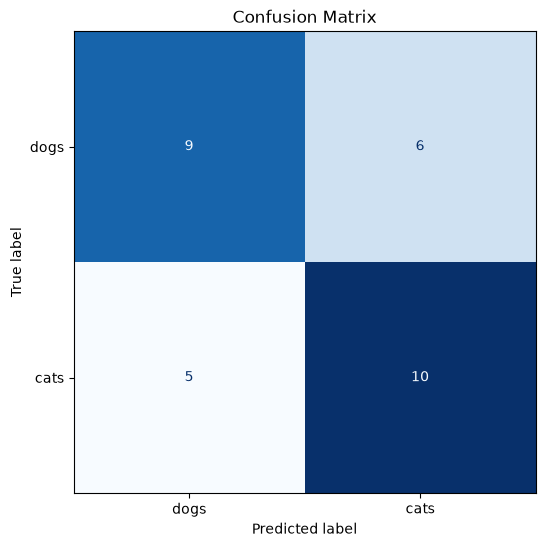

In [20]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

plt.title('Confusion Matrix')
plt.show()

In [21]:
results_df = test_df.copy().reset_index(drop=True)

results_df['true_label'] = y_true
results_df['pred_label'] = y_pred

results_df['confidence'] = np.where(
    y_pred == 1,
    y_prob,
    1 - y_prob
)

errors_df = results_df[
    results_df['true_label'] != results_df['pred_label']
]

print('Всего ошибочных предсказаний:', len(errors_df))

Всего ошибочных предсказаний: 11


In [22]:
for class_id, class_name in enumerate(class_names):

    class_errors = errors_df[
        errors_df['true_label'] == class_id
    ]

    print(f'\nОшибки для класса "{class_name}": {len(class_errors)}')

    for pred_id, pred_name in enumerate(class_names):

        errors_to_class = class_errors[
            class_errors['pred_label'] == pred_id
        ]

        if len(errors_to_class) > 0:
            print(
                f'  → Ошибочно классифицированы как "{pred_name}": '
                f'{len(errors_to_class)}'
            )


Ошибки для класса "dogs": 6
  → Ошибочно классифицированы как "cats": 6

Ошибки для класса "cats": 5
  → Ошибочно классифицированы как "dogs": 5


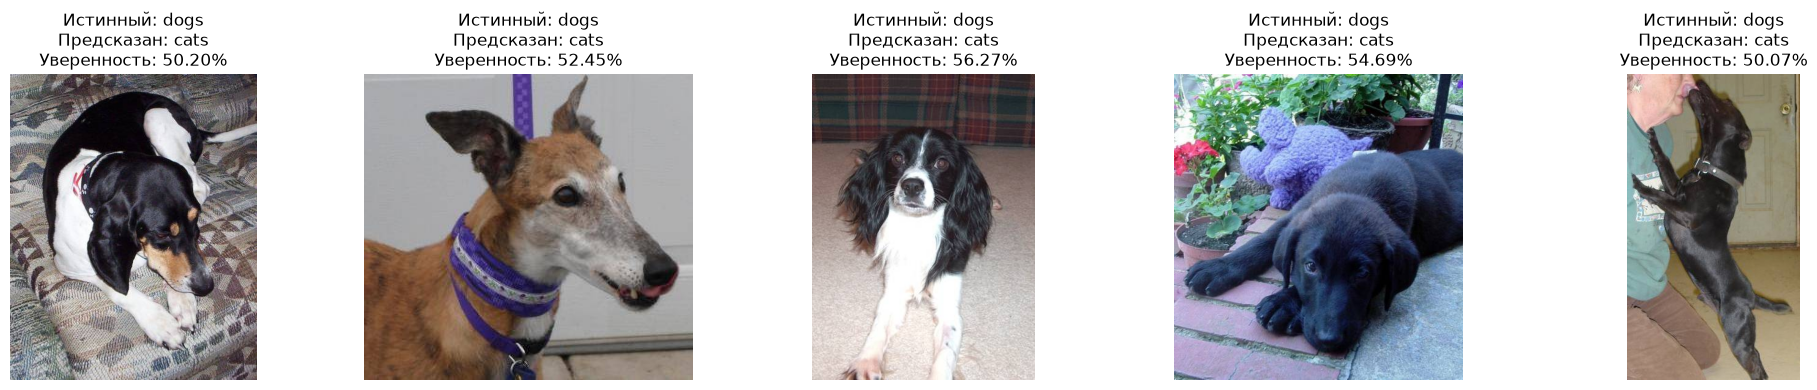

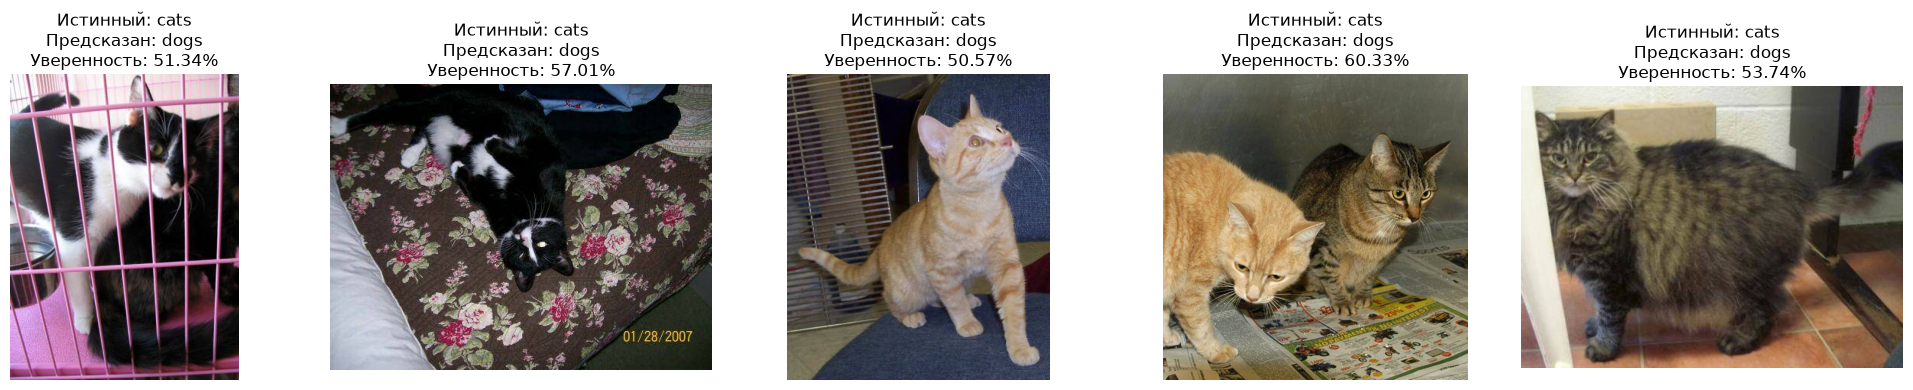

In [23]:
for class_id, class_name in enumerate(class_names):

    class_errors = errors_df[
        errors_df['true_label'] == class_id
    ].head(5)

    if len(class_errors) == 0:
        print(f'Для класса {class_name} ошибок нет.')
        continue

    fig, axes = plt.subplots(
        1,
        len(class_errors),
        figsize=(4 * len(class_errors), 4)
    )

    if len(class_errors) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, class_errors.iterrows()):

        image = plt.imread(row['filepath'])
        ax.imshow(image)

        true_name = class_names[int(row['true_label'])]
        pred_name = class_names[int(row['pred_label'])]

        ax.set_title(
            f'Истинный: {true_name}\n'
            f'Предсказан: {pred_name}\n'
            f'Уверенность: {row["confidence"]:.2%}'
        )

        ax.axis('off')

    plt.tight_layout()
    plt.show()

### VGG

In [24]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

IMG_SIZE = (224, 224)

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)

base_model.trainable = False

inputs = Input(shape=(*IMG_SIZE, 3))

x = tf.keras.layers.Lambda(preprocess_input)(inputs)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

outputs = Dense(1, activation='sigmoid')(x)

vgg_model = Model(inputs, outputs)

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

vgg_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [25]:
history_vgg = vgg_model.fit(
    train_ds, 
    validation_data = val_ds, 
    epochs = 50
)

Epoch 1/50


e:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\lab_01\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.5714 - loss: 2.2418 - precision: 0.5781 - recall: 0.5286 - val_accuracy: 0.8000 - val_loss: 1.0607 - val_precision: 0.8462 - val_recall: 0.7333
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.6500 - loss: 1.4813 - precision: 0.6329 - recall: 0.7143 - val_accuracy: 0.8000 - val_loss: 0.8537 - val_precision: 0.8462 - val_recall: 0.7333
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7571 - loss: 1.1437 - precision: 0.7903 - recall: 0.7000 - val_accuracy: 0.8333 - val_loss: 0.7613 - val_precision: 0.9167 - val_recall: 0.7333
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7429 - loss: 1.2117 - precision: 0.7429 - recall: 0.7429 - val_accuracy: 0.8667 - val_loss: 0.6971 - val_precision: 1.0000 - val_recall: 0.7333
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.8000 - loss: 1.0256 - precision: 0.8500 - recall: 0.7286 - val_accuracy: 0.8667 - val_loss: 0.6292 - val_precision: 1.0000 - val_r

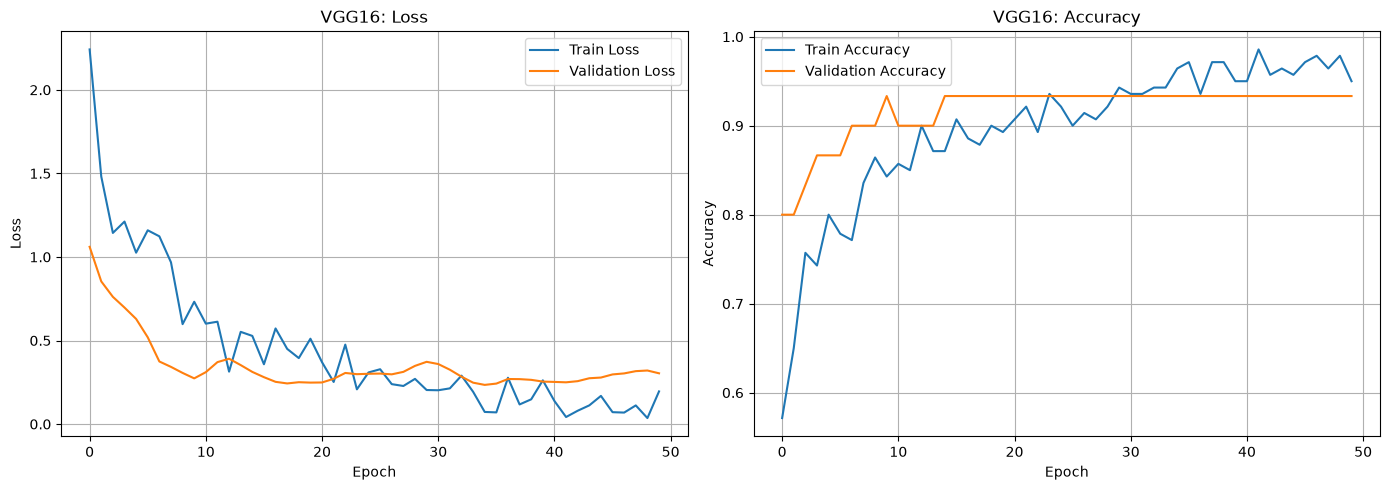

In [26]:
import matplotlib.pyplot as plt

# Получаем историю обучения
history = history_vgg.history

# Создаём два графика
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График Loss
axes[0].plot(history['loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Validation Loss')
axes[0].set_title('VGG16: Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid()

# График Accuracy
axes[1].plot(history['accuracy'], label='Train Accuracy')
axes[1].plot(history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('VGG16: Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [27]:
test_results = vgg_model.evaluate(test_ds, return_dict = True)

print('Результаты VGG16 на тестовой выборке:')

for metric, value in test_results.items():
    print(f'{metric}: {value:.4f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9333 - loss: 0.4177 - precision: 1.0000 - recall: 0.8667
Результаты VGG16 на тестовой выборке:
accuracy: 0.9333
loss: 0.4177
precision: 1.0000
recall: 0.8667


In [28]:
y_prob_vgg = vgg_model.predict(test_ds).ravel()

y_pred_vgg = (y_prob_vgg >= 0.5).astype(int)

y_true = test_df['label'].values

# Рассчитываем основные метрики
print('Метрики классификации VGG16:')
print(f'Accuracy:  {accuracy_score(y_true, y_pred_vgg):.4f}')
print(f'Precision: {precision_score(y_true, y_pred_vgg, zero_division=0):.4f}')
print(f'Recall:    {recall_score(y_true, y_pred_vgg, zero_division=0):.4f}')
print(f'F1-score:  {f1_score(y_true, y_pred_vgg, zero_division=0):.4f}')

# Подробные метрики отдельно для каждого класса
print('\nОтчёт по классам:')
print(classification_report(
    y_true,
    y_pred_vgg,
    target_names=class_names,
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Метрики классификации VGG16:
Accuracy:  0.9333
Precision: 1.0000
Recall:    0.8667
F1-score:  0.9286

Отчёт по классам:
              precision    recall  f1-score   support

        dogs       0.88      1.00      0.94        15
        cats       1.00      0.87      0.93        15

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



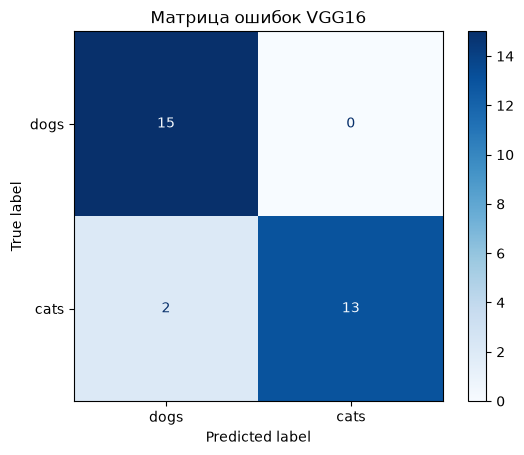

In [29]:
cm_vgg = confusion_matrix(y_true, y_pred_vgg)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_vgg,
    display_labels=class_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Матрица ошибок VGG16')
plt.show()

Всего ошибок VGG16: 2

Ошибки для класса "dogs": 0
Ошибок нет.

Ошибки для класса "cats": 2


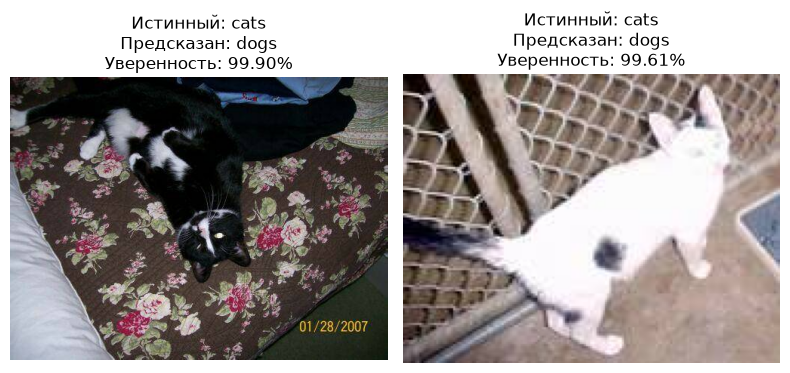

In [30]:
vgg_results = test_df.copy()

vgg_results['true_label'] = y_true
vgg_results['pred_label'] = y_pred_vgg
vgg_results['confidence'] = np.where(
    y_pred_vgg == 1,
    y_prob_vgg,
    1 - y_prob_vgg
)

errors_vgg = vgg_results[
    vgg_results['true_label'] != vgg_results['pred_label']
].copy()

print(f'Всего ошибок VGG16: {len(errors_vgg)}')

for class_id, class_name in enumerate(class_names):

    class_errors = errors_vgg[
        errors_vgg['true_label'] == class_id
    ].head(5)

    print(
        f'\nОшибки для класса "{class_name}": '
        f'{len(errors_vgg[errors_vgg["true_label"] == class_id])}'
    )

    if len(class_errors) == 0:
        print('Ошибок нет.')
        continue

    fig, axes = plt.subplots(
        1,
        len(class_errors),
        figsize=(4 * len(class_errors), 4)
    )

    if len(class_errors) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, class_errors.iterrows()):

        image = plt.imread(row['filepath'])
        ax.imshow(image)

        true_name = class_names[int(row['true_label'])]
        pred_name = class_names[int(row['pred_label'])]

        ax.set_title(
            f'Истинный: {true_name}\n'
            f'Предсказан: {pred_name}\n'
            f'Уверенность: {row["confidence"]:.2%}'
        )

        ax.axis('off')

    plt.tight_layout()
    plt.show()

### YOLO


In [31]:
%pip install -q ultralytics

from ultralytics import YOLO

# Загружаем предобученную YOLO11n.
# При первом запуске веса модели скачаются автоматически.
yolo_model = YOLO('yolo11n.pt')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
dog_row = test_df[test_df['label'] == 0 ].sample(
    n = 1, random_state = 42
).iloc[0]

cat_row = test_df[test_df['label'] == 1].sample(
    n = 1, random_state = 42
).iloc[0]


selected_images = [
    (dog_row['filepath'], 'dog'),
    (cat_row['filepath'], 'cat')
]

for filepath, class_name in selected_images:
    print(f'{class_name}: {filepath}')

dog: lab_08_data\cats_vs_dogs\dogs\dog.37.jpg
cat: lab_08_data\cats_vs_dogs\cats\cat.652.jpg



Истинный класс изображения: dog


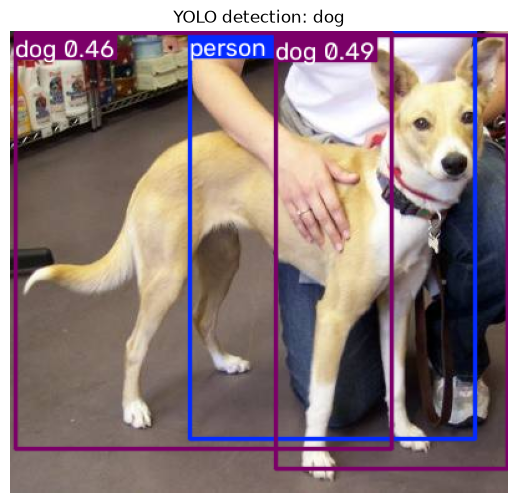

Обнаружен объект: dog, уверенность: 48.99%
Обнаружен объект: dog, уверенность: 46.07%
Обнаружен объект: person, уверенность: 38.84%

Истинный класс изображения: cat


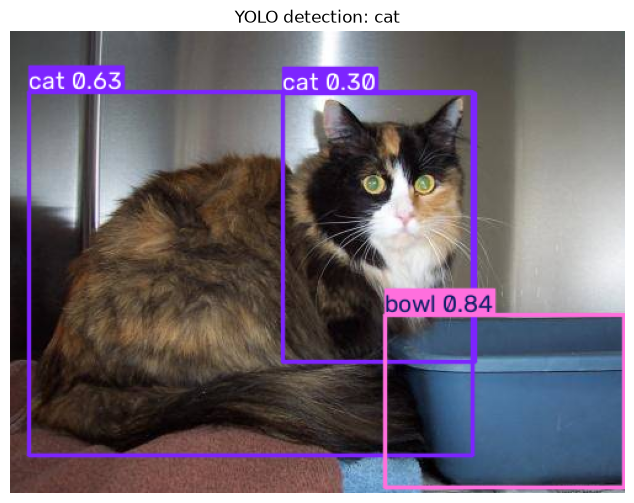

Обнаружен объект: bowl, уверенность: 83.84%
Обнаружен объект: cat, уверенность: 62.98%
Обнаружен объект: cat, уверенность: 30.47%


In [33]:
for filepath, true_class in selected_images:

    print(f'\nИстинный класс изображения: {true_class}')

    results = yolo_model.predict(
        source=filepath,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    plt.figure(figsize=(8, 6))
    plt.imshow(result.plot()[..., ::-1]) 
    plt.title(f'YOLO detection: {true_class}')
    plt.axis('off')
    plt.show()

    if len(result.boxes) == 0:
        print('Объекты не обнаружены.')
    else:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            class_name = yolo_model.names[class_id]

            print(
                f'Обнаружен объект: {class_name}, '
                f'уверенность: {confidence:.2%}'
            )

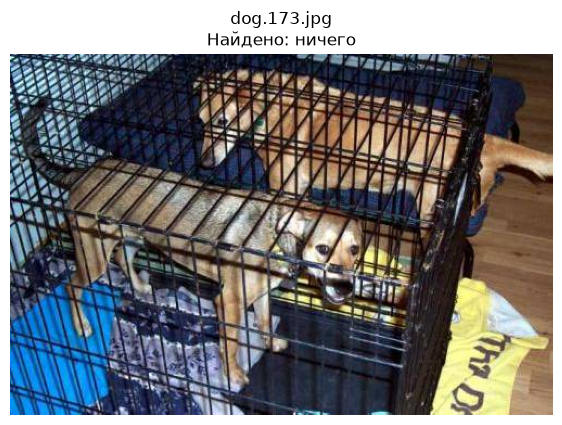

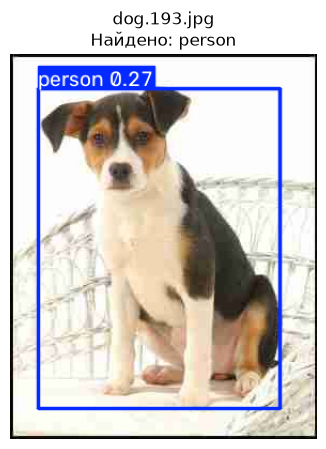

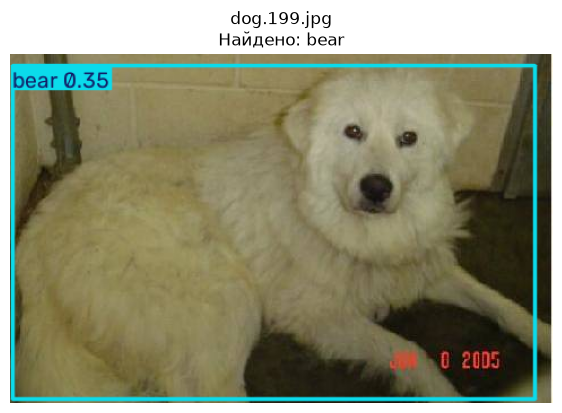

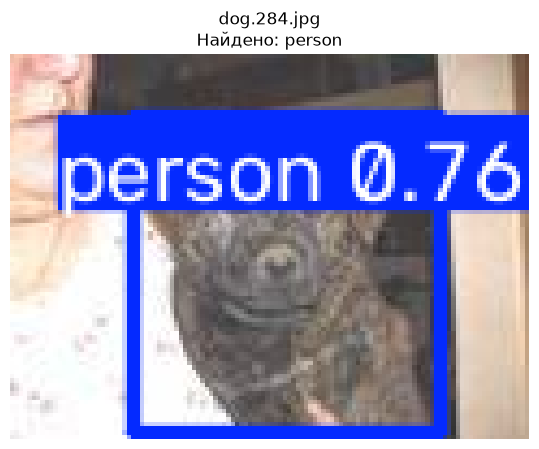

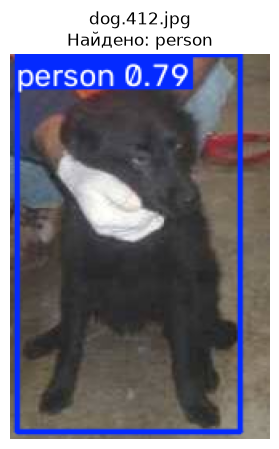

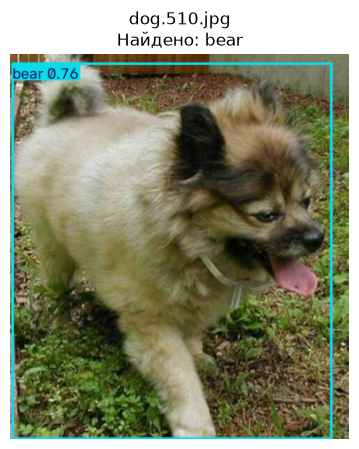

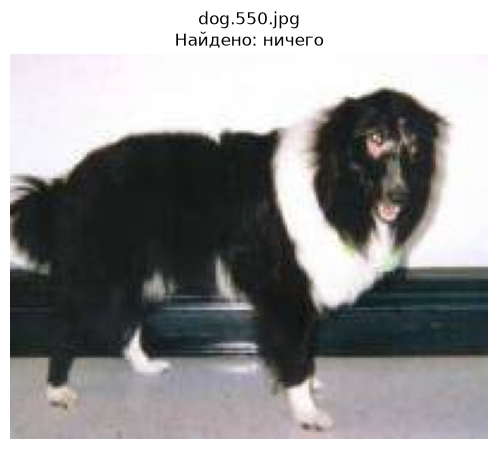

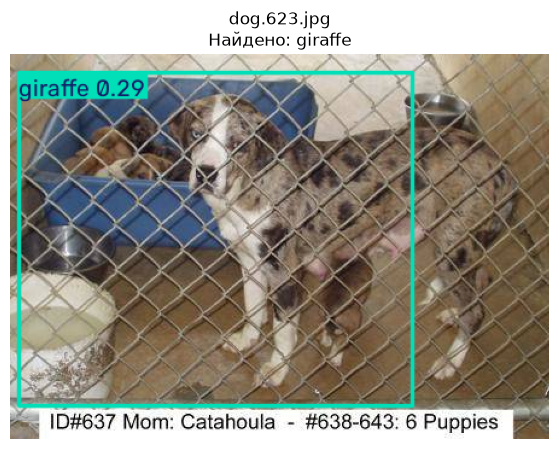

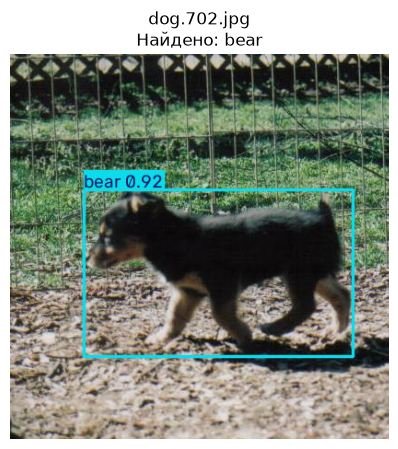

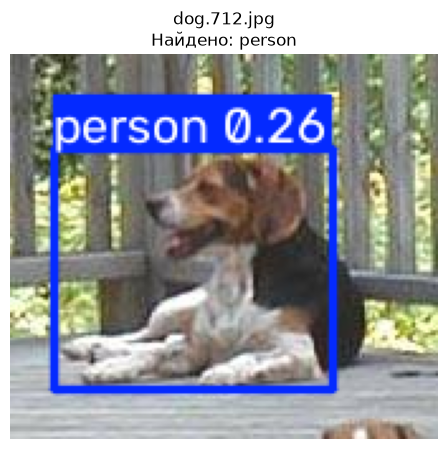

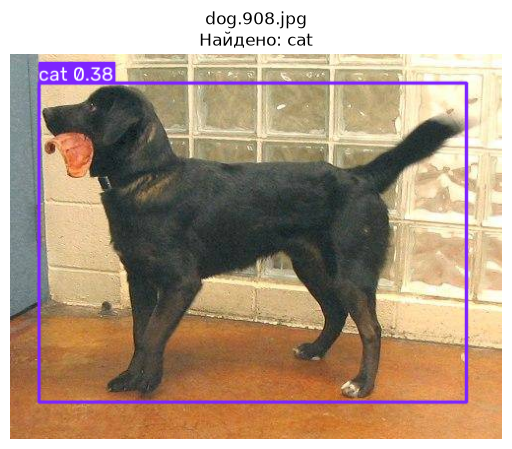

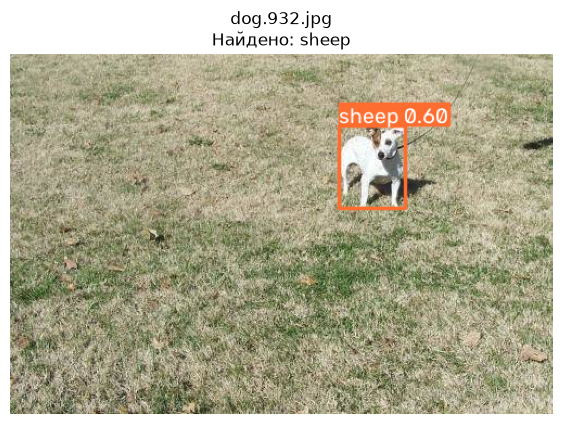

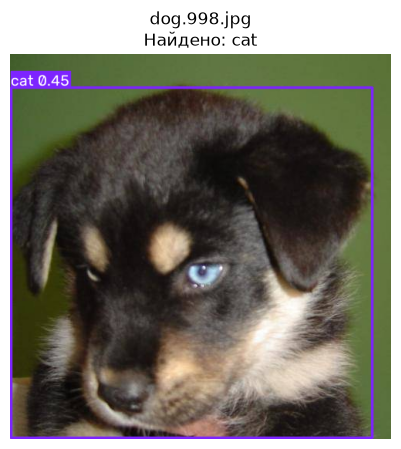

Фотографий без обнаруженной собаки: 13


In [34]:
from pathlib import Path
import matplotlib.pyplot as plt

files = sorted(Path('lab_08_data/cats_vs_dogs/dogs').glob('*.jpg'))
missed_dogs = []

for result in yolo_model.predict(
    source=[str(p) for p in files],
    conf=0.25,
    stream=True,
    verbose=False
):
    detected = [
        result.names[int(class_id)]
        for class_id in result.boxes.cls.tolist()
    ]

    if 'dog' not in detected:
        missed_dogs.append(result.path)

        plt.figure(figsize=(7, 5))
        plt.imshow(result.plot()[..., ::-1])
        plt.title(
            f'{Path(result.path).name}\n'
            f'Найдено: {", ".join(detected) or "ничего"}'
        )
        plt.axis('off')
        plt.show()

print('Фотографий без обнаруженной собаки:', len(missed_dogs))

In [35]:
from pathlib import Path

dog_data_dir = Path('lab_09_data/dog_detection').resolve()
data_yaml = str(dog_data_dir / 'data.yaml')
print('Датасет для дообучения:', dog_data_dir)

Датасет для дообучения: E:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\dog-detection.v1i.yolov8


## 1.7. Дообучение YOLO на размеченных собаках

Используем собственную разметку из Roboflow: 9 изображений train, 2 validation и 2 test. На validation выбираются лучшие веса; test используется после обучения. Формат экспорта YOLOv8 содержит координаты прямоугольных рамок.

In [36]:
from ultralytics import YOLO

dog_model = YOLO('yolov8n.pt')

dog_training = dog_model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640,
    batch=4,
    patience=10,
    workers=0,
    device='cpu',
    seed=42,
    project='runs/dog_detection',
    name='finetune'
)

Ultralytics 8.4.216  Python-3.13.11 torch-2.15.0+cpu CPU (AMD Ryzen 7 5700X 8-Core Processor)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\dog-detection.v1i.yolov8\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

## 1.8. Проверка дообученной модели

Загружаем лучшие веса и проверяем их на test. Затем показываем предсказания исходной и дообученной YOLO на одних и тех же тестовых фотографиях. Тест содержит только две фотографии, поэтому результаты характеризуют эти примеры.

In [37]:
best_dog_model = YOLO(str(dog_model.trainer.best))

dog_test_metrics = best_dog_model.val(
    data=data_yaml,
    split='test',
    imgsz=640,
    batch=2,
    workers=0,
    device='cpu'
)

print(f'mAP50: {dog_test_metrics.box.map50:.4f}')
print(f'mAP50-95: {dog_test_metrics.box.map:.4f}')

Ultralytics 8.4.216  Python-3.13.11 torch-2.15.0+cpu CPU (AMD Ryzen 7 5700X 8-Core Processor)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 292.5±111.8 MB/s, size: 35.0 KB)
val: Scanning E:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\dog-detection.v1i.yolov8\test\labels... 2 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2/2 1.5Kit/s 0.0s
val: New cache created: E:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\dog-detection.v1i.yolov8\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 10.8it/s 0.1s
                   all          2          2      0.952        0.5      0.828      0.513
Speed: 0.9ms preprocess, 38.6ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to E:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\lab_01\runs\detect\val
mAP50: 0.8283
mAP50-95: 0.5132


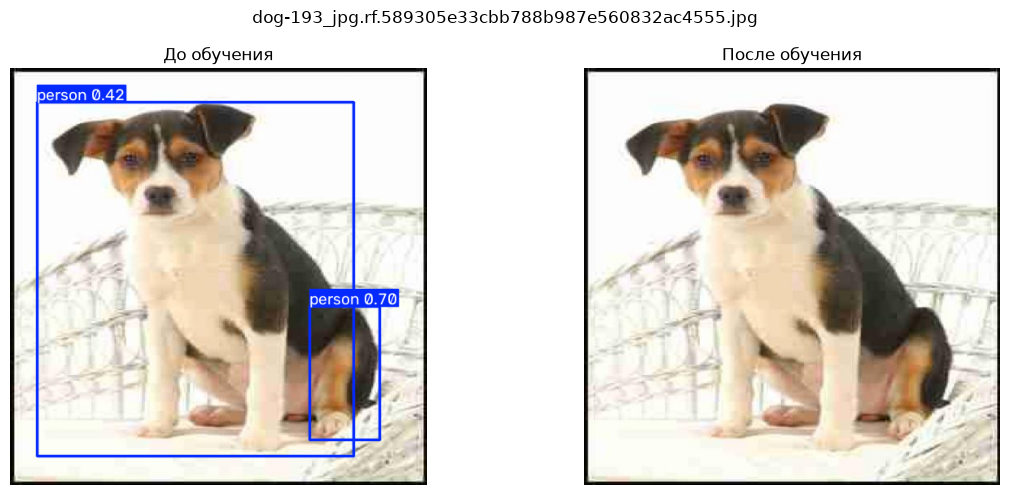

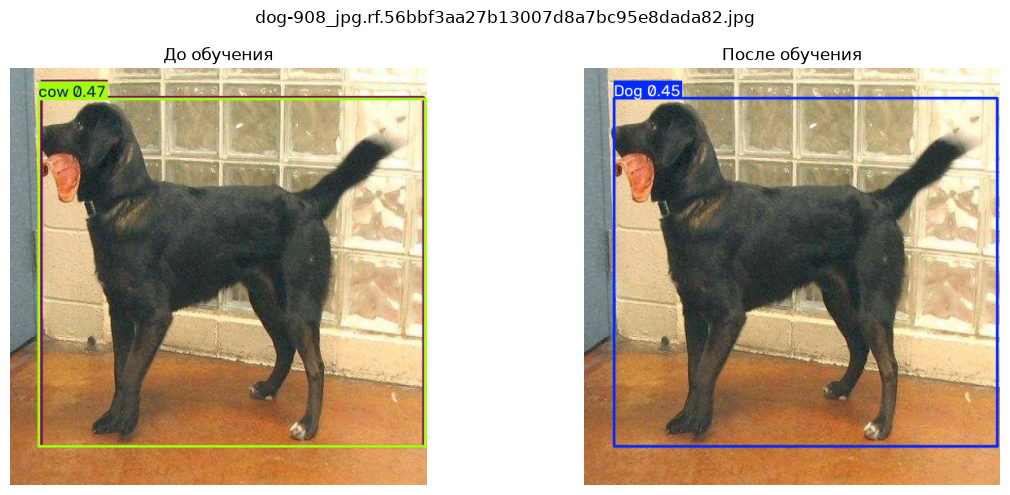

In [38]:
import matplotlib.pyplot as plt

original_dog_model = YOLO('yolov8n.pt')
test_images = sorted((dog_data_dir / 'test' / 'images').glob('*.jpg'))

for image_path in test_images:
    before = original_dog_model.predict(str(image_path), conf=0.25, verbose=False)[0]
    after = best_dog_model.predict(str(image_path), conf=0.25, verbose=False)[0]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, result, title in zip(axes, [before, after], ['До обучения', 'После обучения']):
        ax.imshow(result.plot()[..., ::-1])
        ax.set_title(title)
        ax.axis('off')
    fig.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()

## Выводы

Для классификации кошек и собак подготовлены 200 изображений: 140 для обучения, по 30 для валидации и тестирования. Собственная CNN получила test accuracy 0,6333, VGG16 с предобученной основой — 0,9333. На этой выборке VGG16 распознаёт классы лучше: у неё 2 ошибки из 30, у CNN — 11.

При проверке исходной YOLO11 найдены 13 фотографий, на которых она не обнаружила собаку при пороге confidence 0,25. Собаки на этих фотографиях размечены прямоугольными рамками в Roboflow. Для дообучения YOLOv8 набор разделён на 9 изображений train, 2 validation и 2 test. Это отобранные сложные случаи, поэтому результаты относятся именно к такому набору.

Дообучение YOLOv8 остановилось после 11 эпох; лучшей по валидации стала первая эпоха. На тестовых изображениях получены mAP50 = 0,8283 и mAP50–95 = 0,5132.

В сравнении на одних и тех же тестовых кадрах исходная YOLOv8 определяла собаку на `dog-908` как корову, а дообученная модель нашла объект класса Dog. На `dog-193` исходная модель выдавала рамки person, а дообученная при confidence 0,25 не выдала рамку собаки. Ошибка на этом изображении осталась.

Дообучение помогло на одном из двух показанных примеров. Двух тестовых фотографий недостаточно, чтобы сделать вывод об улучшении на произвольных изображениях собак. Для дальнейшей проверки нужен более крупный независимый набор; результаты классификации CNN/VGG и метрики детектора YOLO напрямую не сравниваются.